In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error
from statsmodels.graphics.tsaplots import plot_acf

In [2]:
df = pd.read_csv("./data/ETTh1.csv")

In [3]:
df.head()

,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
0,2016-07-01 00:00:00,5.827,2.009,1.599,0.462,4.203,1.340,30.531000
1,2016-07-01 01:00:00,5.693,2.076,1.492,0.426,4.142,1.371,27.787001
2,2016-07-01 02:00:00,5.157,1.741,1.279,0.355,3.777,1.218,27.787001
3,2016-07-01 03:00:00,5.090,1.942,1.279,0.391,3.807,1.279,25.044001
4,2016-07-01 04:00:00,5.358,1.942,1.492,0.462,3.868,1.279,21.948000


In [ ]:
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17420 entries, 0 to 17419
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    17420 non-null  datetime64[us]
 1   HUFL    17420 non-null  float64       
 2   HULL    17420 non-null  float64       
 3   MUFL    17420 non-null  float64       
 4   MULL    17420 non-null  float64       
 5   LUFL    17420 non-null  float64       
 6   LULL    17420 non-null  float64       
 7   OT      17420 non-null  float64       
dtypes: datetime64[us](1), float64(7)
memory usage: 1.1 MB


In [6]:
print("Start:", df["date"].min())
print("End:", df["date"].max())
print("Number of observations:", len(df))

Start: 2016-07-01 00:00:00
End: 2018-06-26 19:00:00
Number of observations: 17420


In [7]:
df["date"].diff().value_counts().head()

date
0 days 01:00:00    17419
Name: count, dtype: int64

In [8]:
df.isnull().sum()

date    0
HUFL    0
HULL    0
MUFL    0
MULL    0
LUFL    0
LULL    0
OT      0
dtype: int64

In [9]:
df.describe()

,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
count,17420,17420.000000,17420.000000,17420.000000,17420.000000,17420.000000,17420.000000,17420.000000
mean,2017-06-28 21:30:00,7.375141,2.242242,4.300239,0.881568,3.066062,0.856932,13.324672
min,2016-07-01 00:00:00,-22.705999,-4.756000,-25.087999,-5.934000,-1.188000,-1.371000,-4.080000
25%,2016-12-29 10:45:00,5.827000,0.737000,3.296000,-0.284000,2.315000,0.670000,6.964000
50%,2017-06-28 21:30:00,8.774000,2.210000,5.970000,0.959000,2.833000,0.975000,11.396000
75%,2017-12-27 08:15:00,11.788000,3.684000,8.635000,2.203000,3.625000,1.218000,18.079000
max,2018-06-26 19:00:00,23.643999,10.114000,17.341000,7.747000,8.498000,3.046000,46.007000
std,NaN,7.067744,2.042342,6.826978,1.809293,1.164506,0.599552,8.566946


### Data Understanding

#### OT Trend

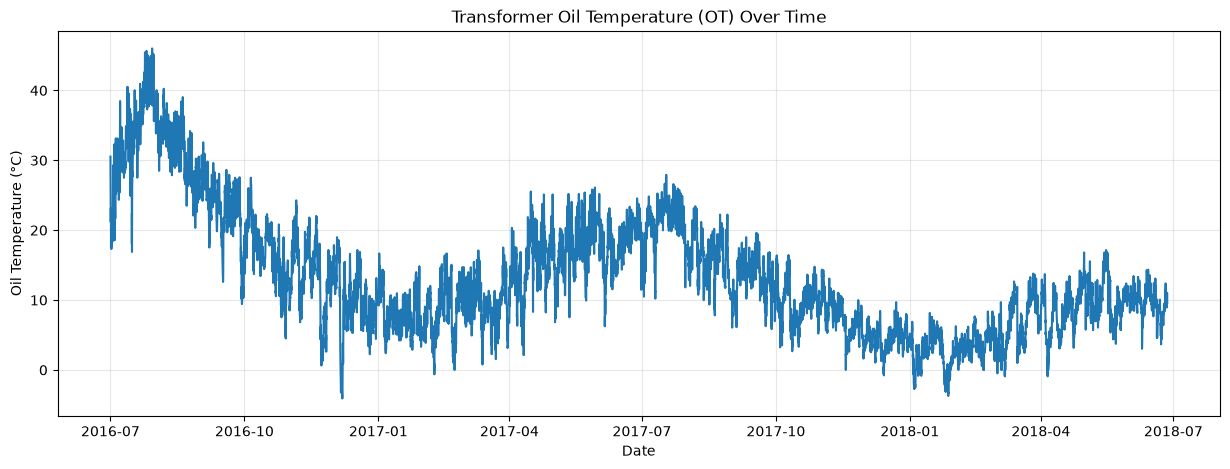

In [10]:
plt.figure(figsize=(15, 5))

plt.plot(df["date"], df["OT"])

plt.xlabel("Date")
plt.ylabel("Oil Temperature (°C)")
plt.title("Transformer Oil Temperature (OT) Over Time")

plt.grid(True, alpha=0.3)
plt.show()

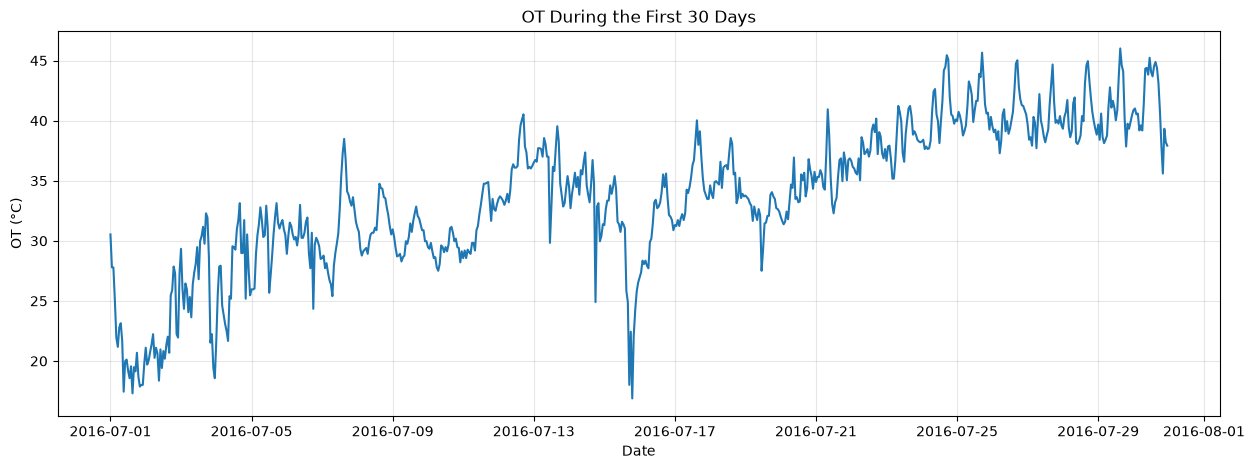

In [11]:
# 24h * 30 days = 720 hours
one_month = df.iloc[:24 * 30]

plt.figure(figsize=(15, 5))

plt.plot(one_month["date"], one_month["OT"])

plt.xlabel("Date")
plt.ylabel("OT (°C)")
plt.title("OT During the First 30 Days")

plt.grid(True, alpha=0.3)
plt.show()

#### Daily Cycle

In [12]:
df["hour"] = df["date"].dt.hour

daily_cycle = df.groupby("hour")["OT"].mean()

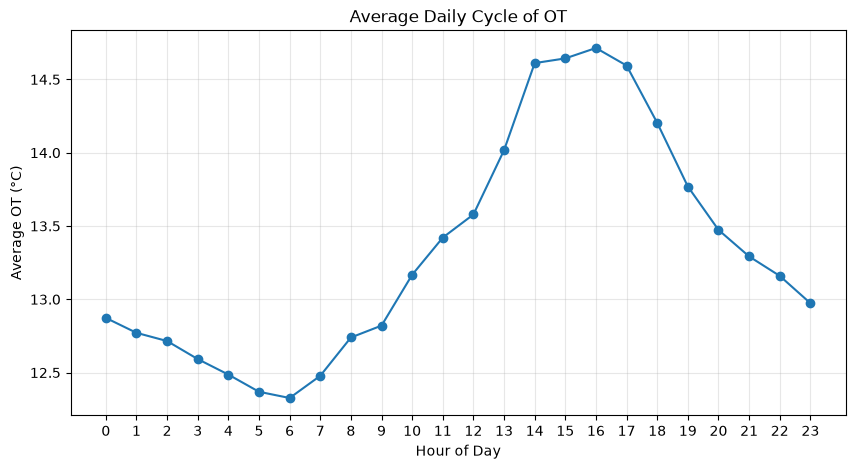

In [13]:
# average OT by hour
plt.figure(figsize=(10, 5))

plt.plot(
    daily_cycle.index,
    daily_cycle.values,
    marker="o"
)

plt.xlabel("Hour of Day")
plt.ylabel("Average OT (°C)")
plt.title("Average Daily Cycle of OT")

plt.xticks(range(24))
plt.grid(alpha=0.3)

plt.show()

#### Weekly Cycle

In [14]:
df["day_of_week"] = df["date"].dt.dayofweek

weekly_cycle = df.groupby("day_of_week")["OT"].mean()

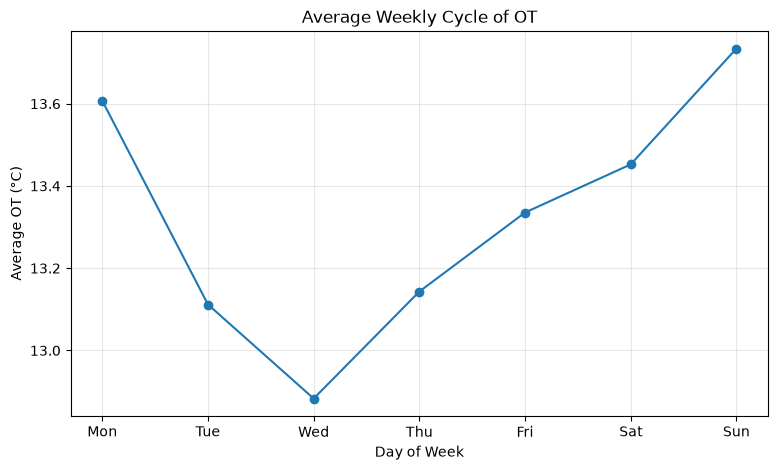

In [15]:
# average OT by weekday
days = [
    "Mon", "Tue", "Wed",
    "Thu", "Fri", "Sat", "Sun"
]

plt.figure(figsize=(9, 5))

plt.plot(
    weekly_cycle.index,
    weekly_cycle.values,
    marker="o"
)

plt.xticks(
    range(7),
    days
)

plt.xlabel("Day of Week")
plt.ylabel("Average OT (°C)")
plt.title("Average Weekly Cycle of OT")

plt.grid(alpha=0.3)

plt.show()

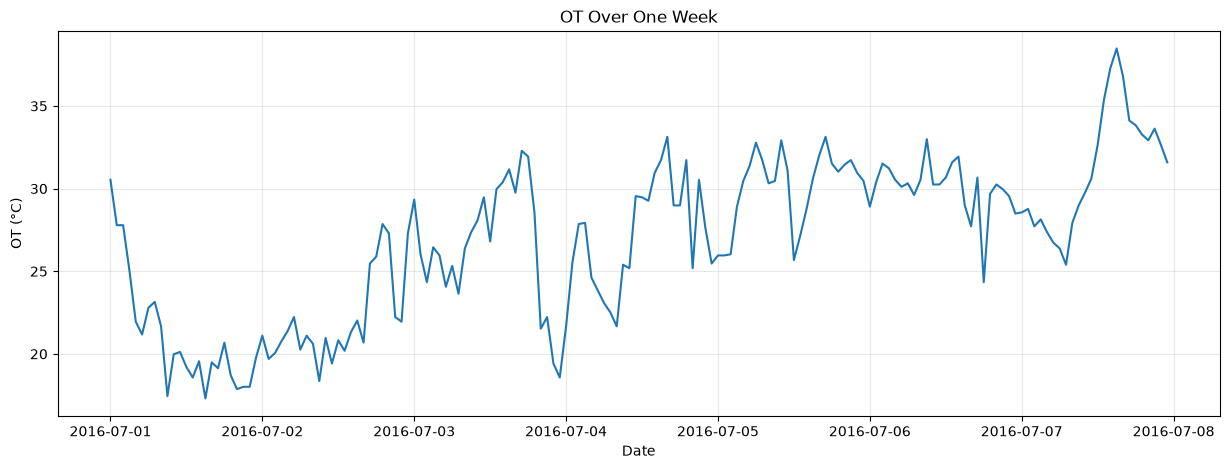

In [16]:
one_week = df.iloc[:168]

plt.figure(figsize=(15, 5))

plt.plot(one_week["date"], one_week["OT"])

plt.xlabel("Date")
plt.ylabel("OT (°C)")
plt.title("OT Over One Week")

plt.grid(True, alpha=0.3)

plt.show()

#### Correlation

In [17]:
features = [
    "HUFL",
    "HULL",
    "MUFL",
    "MULL",
    "LUFL",
    "LULL",
    "OT"
]

correlation = df[features].corr()

correlation

,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
HUFL,1.000000,0.114672,0.987355,0.066002,0.291418,0.023606,0.059916
HULL,0.114672,1.000000,0.068817,0.930491,0.259487,0.377641,0.224354
MUFL,0.987355,0.068817,1.000000,0.046266,0.177491,-0.046519,0.050854
MULL,0.066002,0.930491,0.046266,1.000000,0.128607,0.069419,0.220004
LUFL,0.291418,0.259487,0.177491,0.128607,1.000000,0.334563,0.118836
LULL,0.023606,0.377641,-0.046519,0.069419,0.334563,1.000000,0.067455
OT,0.059916,0.224354,0.050854,0.220004,0.118836,0.067455,1.000000


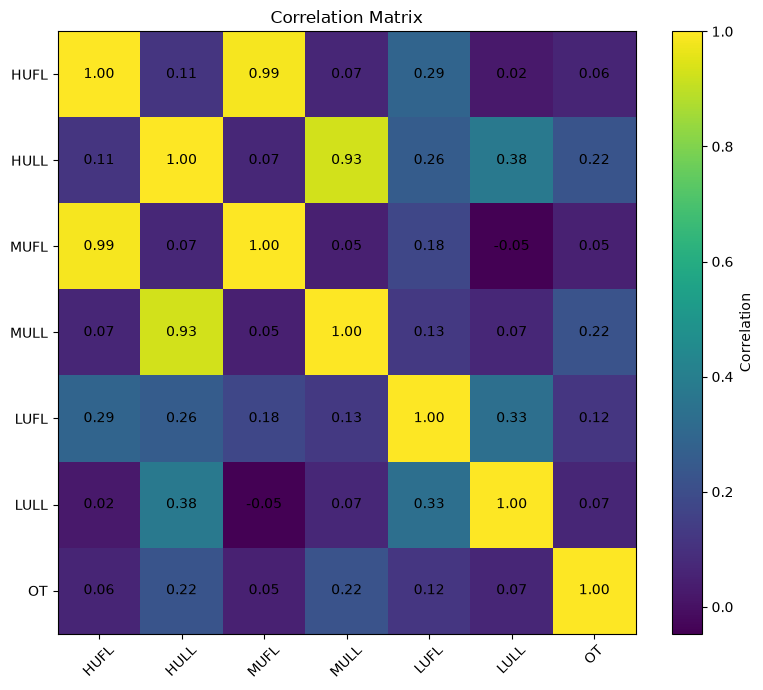

In [18]:
plt.figure(figsize=(8, 7))

plt.imshow(correlation, aspect="auto")

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(features)),
    features,
    rotation=45
)

plt.yticks(
    range(len(features)),
    features
)

plt.title("Correlation Matrix")

for i in range(len(features)):
    for j in range(len(features)):
        plt.text(
            j,
            i,
            f"{correlation.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

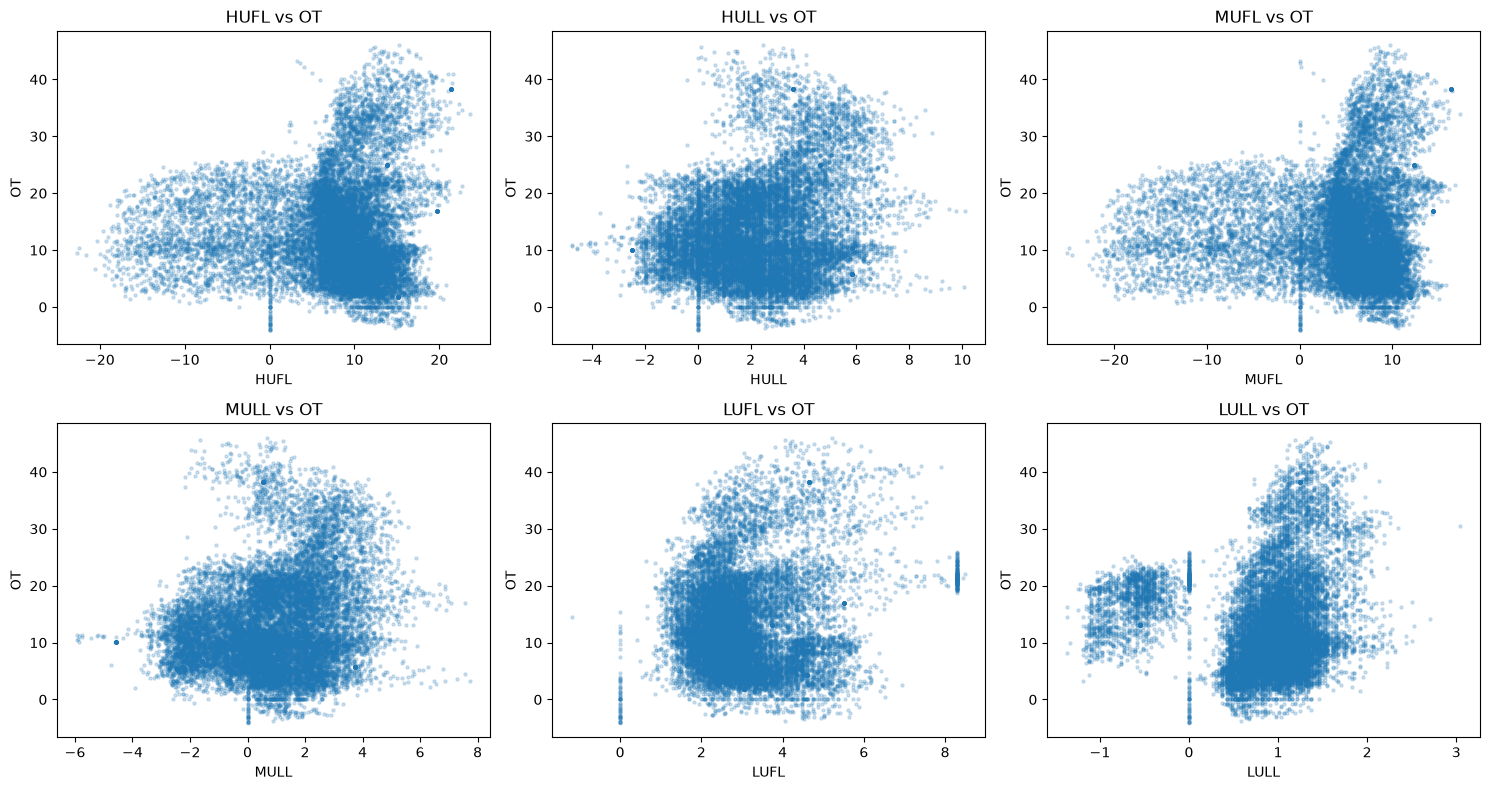

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

input_features = [
    "HUFL",
    "HULL",
    "MUFL",
    "MULL",
    "LUFL",
    "LULL"
]

for ax, feature in zip(axes.flatten(), input_features):
    ax.scatter(
        df[feature],
        df["OT"],
        alpha=0.2,
        s=5
    )

    ax.set_xlabel(feature)
    ax.set_ylabel("OT")
    ax.set_title(f"{feature} vs OT")

plt.tight_layout()
plt.show()

#### Autocorrelation Function (ACF)

<Figure size 1400x500 with 0 Axes>

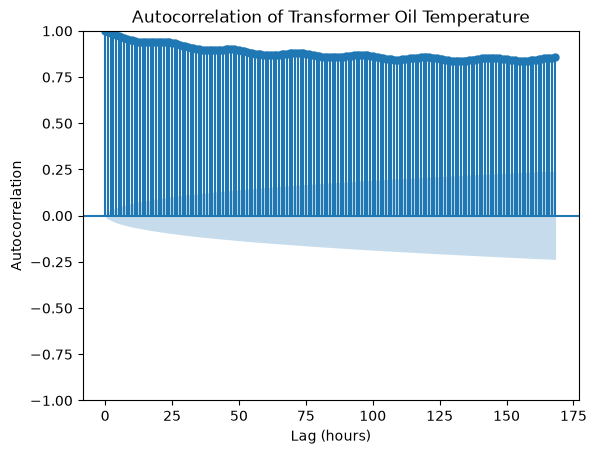

In [20]:
plt.figure(figsize=(14, 5))

plot_acf(
    df["OT"],
    lags=168
)

plt.xlabel("Lag (hours)")
plt.ylabel("Autocorrelation")
plt.title("Autocorrelation of Transformer Oil Temperature")

plt.show()

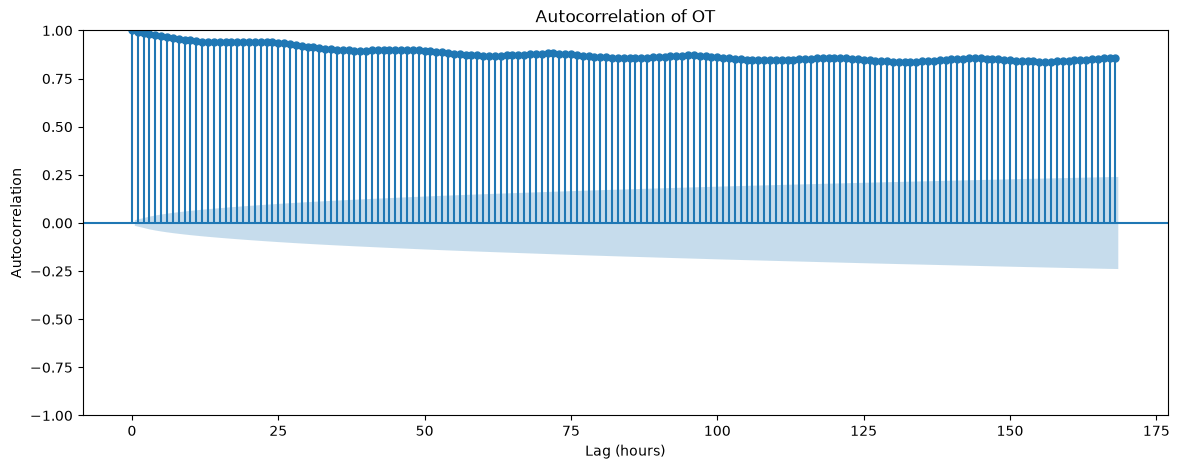

In [21]:
fig, ax = plt.subplots(figsize=(14, 5))

plot_acf(
    df["OT"],
    lags=168,
    ax=ax
)

ax.set_xlabel("Lag (hours)")
ax.set_ylabel("Autocorrelation")
ax.set_title("Autocorrelation of OT")

plt.show()

In [22]:
for lag in [1, 24, 168]:
    corr = df["OT"].autocorr(lag=lag)

    print(
        f"Lag {lag:3d} hours: {corr:.4f}"
    )

Lag   1 hours: 0.9943
Lag  24 hours: 0.9406
Lag 168 hours: 0.8701


### Time-based split

In [23]:
model_df = df[
    [
        "date",
        "HUFL",
        "HULL",
        "MUFL",
        "MULL",
        "LUFL",
        "LULL",
        "OT"
    ]
].copy()

model_df.head()

,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
0,2016-07-01 00:00:00,5.827,2.009,1.599,0.462,4.203,1.340,30.531000
1,2016-07-01 01:00:00,5.693,2.076,1.492,0.426,4.142,1.371,27.787001
2,2016-07-01 02:00:00,5.157,1.741,1.279,0.355,3.777,1.218,27.787001
3,2016-07-01 03:00:00,5.090,1.942,1.279,0.391,3.807,1.279,25.044001
4,2016-07-01 04:00:00,5.358,1.942,1.492,0.462,3.868,1.279,21.948000


In [24]:
model_df = (
    model_df
    .sort_values("date")
    .reset_index(drop=True)
)

In [25]:
start_date = model_df["date"].min()

train_end = start_date + pd.DateOffset(months=12)
val_end   = train_end + pd.DateOffset(months=4)
test_end  = val_end + pd.DateOffset(months=4)

print("Dataset starts :", start_date)
print("Train ends     :", train_end)
print("Validation ends:", val_end)
print("Test ends      :", test_end)

Dataset starts : 2016-07-01 00:00:00
Train ends     : 2017-07-01 00:00:00
Validation ends: 2017-11-01 00:00:00
Test ends      : 2018-03-01 00:00:00


In [26]:
train_df = model_df[
    (model_df["date"] >= start_date) &
    (model_df["date"] < train_end)
].copy()

val_df = model_df[
    (model_df["date"] >= train_end) &
    (model_df["date"] < val_end)
].copy()

test_df = model_df[
    (model_df["date"] >= val_end) &
    (model_df["date"] < test_end)
].copy()

In [27]:
print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)

Train shape: (8760, 8)
Validation shape: (2952, 8)
Test shape: (2880, 8)


In [28]:
print(
    "Train:",
    train_df["date"].min(),
    "→",
    train_df["date"].max()
)

print(
    "Validation:",
    val_df["date"].min(),
    "→",
    val_df["date"].max()
)

print(
    "Test:",
    test_df["date"].min(),
    "→",
    test_df["date"].max()
)

Train: 2016-07-01 00:00:00 → 2017-06-30 23:00:00
Validation: 2017-07-01 00:00:00 → 2017-10-31 23:00:00
Test: 2017-11-01 00:00:00 → 2018-02-28 23:00:00


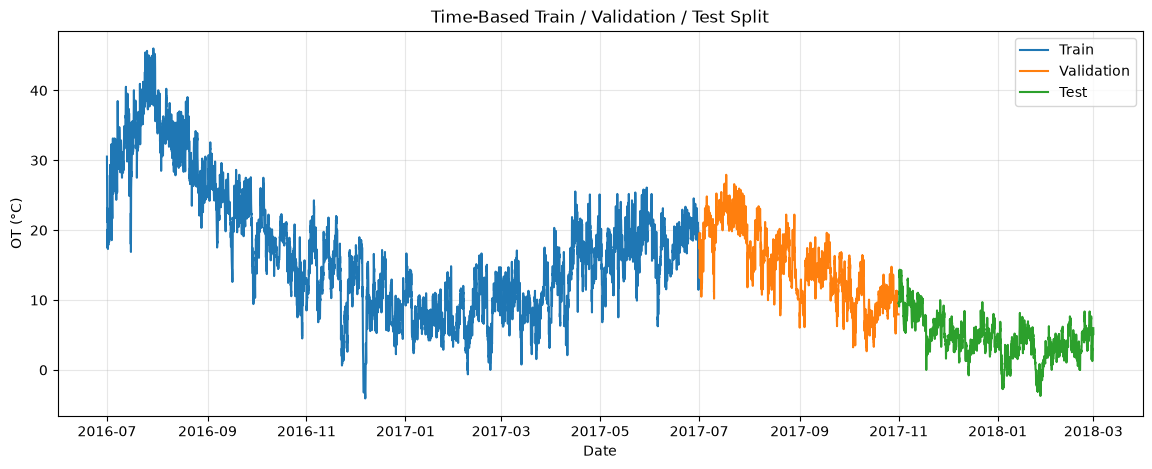

In [29]:
plt.figure(figsize=(14, 5))

plt.plot(
    train_df["date"],
    train_df["OT"],
    label="Train"
)

plt.plot(
    val_df["date"],
    val_df["OT"],
    label="Validation"
)

plt.plot(
    test_df["date"],
    test_df["OT"],
    label="Test"
)

plt.xlabel("Date")
plt.ylabel("OT (°C)")
plt.title("Time-Based Train / Validation / Test Split")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [30]:
def create_baseline_windows(data, L, H):

    ot = data["OT"].to_numpy()

    y_true = []
    naive_pred = []
    seasonal_pred = []
    forecast_dates = []

    # We need at least 24 hours for seasonal naive
    if L < 24:
        raise ValueError(
            "L must be at least 24 for seasonal naive forecasting."
        )

    # i = first future observation
    for i in range(L, len(data) - H + 1):

        # -------------------------
        # Historical input
        # -------------------------
        history = ot[i - L:i]

        # -------------------------
        # Actual future target
        # -------------------------
        future = ot[i:i + H]

        # -------------------------
        # Naive forecast
        # -------------------------
        last_value = history[-1]

        naive = np.repeat(
            last_value,
            H
        )

        # -------------------------
        # Seasonal naive forecast
        # -------------------------
        last_24_hours = history[-24:]

        repeats = int(np.ceil(H / 24))

        seasonal = np.tile(
            last_24_hours,
            repeats
        )[:H]

        # Save
        y_true.append(future)
        naive_pred.append(naive)
        seasonal_pred.append(seasonal)

        forecast_dates.append(
            data["date"].iloc[i]
        )

    return (
        np.array(y_true),
        np.array(naive_pred),
        np.array(seasonal_pred),
        np.array(forecast_dates)
    )

In [31]:
L = 24
H = 24

y_val_true, naive_val, seasonal_val, val_dates = (
    create_baseline_windows(
        val_df,
        L=L,
        H=H
    )
)

In [32]:
print("Actual shape:", y_val_true.shape)
print("Naive shape:", naive_val.shape)
print("Seasonal naive shape:", seasonal_val.shape)

Actual shape: (2905, 24)
Naive shape: (2905, 24)
Seasonal naive shape: (2905, 24)


In [33]:
print("Actual:")
print(y_val_true[0])

print("\nNaive:")
print(naive_val[0])

print("\nSeasonal Naive:")
print(seasonal_val[0])

Actual:
[16.88299942 16.81299973 16.46100044 15.68700027 12.23999977 11.5369997
 12.6619997  14.27999973 12.94400024 10.48200035 12.31099987 16.10899925
 14.70300007 13.71800041 16.60199928 18.00900078 18.5720005  18.00900078
 13.64700031 12.38099957 15.68700027 15.19499969 16.32099915 17.30500031]

Naive:
[17.37599945 17.37599945 17.37599945 17.37599945 17.37599945 17.37599945
 17.37599945 17.37599945 17.37599945 17.37599945 17.37599945 17.37599945
 17.37599945 17.37599945 17.37599945 17.37599945 17.37599945 17.37599945
 17.37599945 17.37599945 17.37599945 17.37599945 17.37599945 17.37599945]

Seasonal Naive:
[18.07900047 17.37599945 18.07900047 17.86800003 17.72699928 18.07900047
 18.92300034 18.92300034 19.62700081 16.95400047 13.15499973 13.50699997
 15.0539999  15.40600014 17.93799973 18.00900078 17.72699928 16.46100044
 18.43099976 18.29000092 18.5720005  18.00900078 17.79800034 17.37599945]


In [34]:
def calculate_metrics(y_true, y_pred):

    mae = np.mean(
        np.abs(y_true - y_pred)
    )

    rmse = np.sqrt(
        np.mean(
            (y_true - y_pred) ** 2
        )
    )

    return mae, rmse

In [35]:
naive_mae, naive_rmse = calculate_metrics(
    y_val_true,
    naive_val
)

print(f"Naive MAE : {naive_mae:.4f} °C")
print(f"Naive RMSE: {naive_rmse:.4f} °C")

Naive MAE : 1.7837 °C
Naive RMSE: 2.3977 °C


In [36]:
seasonal_mae, seasonal_rmse = calculate_metrics(
    y_val_true,
    seasonal_val
)

print(
    f"Seasonal Naive MAE : "
    f"{seasonal_mae:.4f} °C"
)

print(
    f"Seasonal Naive RMSE: "
    f"{seasonal_rmse:.4f} °C"
)

Seasonal Naive MAE : 1.9522 °C
Seasonal Naive RMSE: 2.6665 °C


In [37]:
baseline_comparison = pd.DataFrame({
    "Model": [
        "Naive",
        "Seasonal Naive"
    ],

    "MAE": [
        naive_mae,
        seasonal_mae
    ],

    "RMSE": [
        naive_rmse,
        seasonal_rmse
    ]
})

baseline_comparison.round(4)

,Model,MAE,RMSE
0,Naive,1.7837,2.3977
1,Seasonal Naive,1.9522,2.6665


In [38]:
example = 0

forecast_time = pd.date_range(
    start=val_dates[example],
    periods=H,
    freq="h"
)

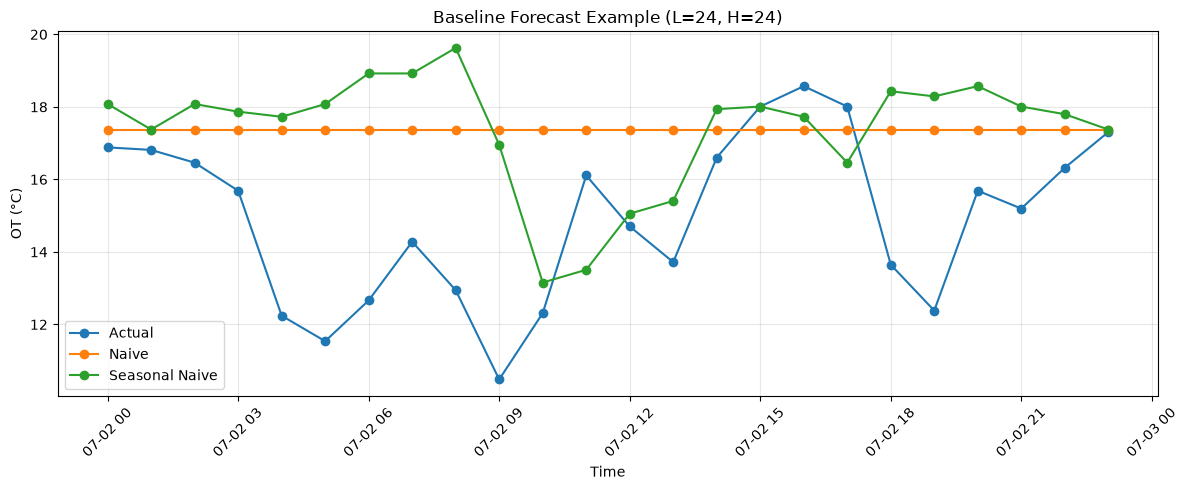

In [39]:
plt.figure(figsize=(12, 5))

plt.plot(
    forecast_time,
    y_val_true[example],
    marker="o",
    label="Actual"
)

plt.plot(
    forecast_time,
    naive_val[example],
    marker="o",
    label="Naive"
)

plt.plot(
    forecast_time,
    seasonal_val[example],
    marker="o",
    label="Seasonal Naive"
)

plt.xlabel("Time")
plt.ylabel("OT (°C)")
plt.title(
    f"Baseline Forecast Example "
    f"(L={L}, H={H})"
)

plt.legend()
plt.grid(alpha=0.3)

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [40]:
L_values = [24, 168]
H_values = [1, 24, 96]

baseline_results = []

In [41]:
for L in L_values:

    for H in H_values:

        (
            y_true,
            naive_pred,
            seasonal_pred,
            forecast_dates
        ) = create_baseline_windows(
            val_df,
            L=L,
            H=H
        )

        # Naive
        naive_mae, naive_rmse = (
            calculate_metrics(
                y_true,
                naive_pred
            )
        )

        baseline_results.append({
            "L": L,
            "H": H,
            "Model": "Naive",
            "MAE": naive_mae,
            "RMSE": naive_rmse
        })

        # Seasonal naive
        seasonal_mae, seasonal_rmse = (
            calculate_metrics(
                y_true,
                seasonal_pred
            )
        )

        baseline_results.append({
            "L": L,
            "H": H,
            "Model": "Seasonal Naive",
            "MAE": seasonal_mae,
            "RMSE": seasonal_rmse
        })

In [42]:
baseline_results_df = pd.DataFrame(
    baseline_results
)

baseline_results_df.round(4)

,L,H,Model,MAE,RMSE
0,24,1,Naive,0.5937,0.9010
1,24,1,Seasonal Naive,1.9555,2.6701
2,24,24,Naive,1.7837,2.3977
3,24,24,Seasonal Naive,1.9522,2.6665
4,24,96,Naive,2.5513,3.3410
5,24,96,Seasonal Naive,2.5534,3.3535
6,168,1,Naive,0.5841,0.8848
7,168,1,Seasonal Naive,1.9539,2.6647
8,168,24,Naive,1.8005,2.4149
9,168,24,Seasonal Naive,1.9608,2.6724


### Step 3

In [43]:
feature_cols = [
    "HUFL",
    "HULL",
    "MUFL",
    "MULL",
    "LUFL",
    "LULL",
    "OT"
]

In [44]:
train_mean = train_df[feature_cols].mean()
train_std = train_df[feature_cols].std()

print("Training mean:")
print(train_mean)

print("\nTraining std:")
print(train_std)

Training mean:
HUFL     7.909795
HULL     2.019931
MUFL     5.045573
MULL     0.763926
LUFL     2.787863
LULL     0.771786
OT      17.169089
dtype: float64

Training std:
HUFL    5.820496
HULL    2.080298
MUFL    5.534967
MULL    1.922876
LUFL    1.020194
LULL    0.642145
OT      9.122925
dtype: float64


In [45]:
def normalize_period(data, mean, std):
    data_scaled = data.copy()

    data_scaled[feature_cols] = (
        data_scaled[feature_cols] - mean
    ) / std

    return data_scaled

In [46]:
train_scaled = normalize_period(
    train_df,
    train_mean,
    train_std
)

val_scaled = normalize_period(
    val_df,
    train_mean,
    train_std
)

In [47]:
def create_windows(data, L, H):

    values = data[feature_cols].to_numpy(
        dtype=np.float32
    )

    ot_index = feature_cols.index("OT")

    X = []
    y = []

    for i in range(L, len(values) - H + 1):

        # Past L hours, all 7 variables
        X_window = values[i - L:i]

        # Future H hours, OT only
        y_window = values[
            i:i + H,
            ot_index
        ]

        X.append(X_window)
        y.append(y_window)

    return (
        np.array(X, dtype=np.float32),
        np.array(y, dtype=np.float32)
    )

In [48]:
L = 24
H = 24

X_train, y_train = create_windows(
    train_scaled,
    L=L,
    H=H
)

In [49]:
X_val, y_val = create_windows(
    val_scaled,
    L=L,
    H=H
)

In [50]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

X_train: (8713, 24, 7)
y_train: (8713, 24)
X_val: (2905, 24, 7)
y_val: (2905, 24)


In [54]:
X_train_flat = X_train.reshape(
    X_train.shape[0],
    -1
)

X_val_flat = X_val.reshape(
    X_val.shape[0],
    -1
)

In [55]:
print("Original:", X_train.shape)
print("Flattened:", X_train_flat.shape)

Original: (8713, 24, 7)
Flattened: (8713, 168)


In [56]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()
linear_model.fit(X_train_flat,y_train)
linear_val_pred_norm = linear_model.predict(X_val_flat)

In [57]:
print(linear_val_pred_norm.shape)

(2905, 24)


In [58]:
def denormalize_ot(values):

    return (
        values * train_std["OT"]
        + train_mean["OT"]
    )

In [59]:
y_val_original = denormalize_ot(
    y_val
)

linear_val_pred = denormalize_ot(
    linear_val_pred_norm
)

In [60]:
linear_mae, linear_rmse = calculate_metrics(
    y_val_original,
    linear_val_pred
)

print(
    f"Linear Regression MAE : "
    f"{linear_mae:.4f} °C"
)

print(
    f"Linear Regression RMSE: "
    f"{linear_rmse:.4f} °C"
)

Linear Regression MAE : 2.3428 °C
Linear Regression RMSE: 4.4129 °C


In [65]:
import random

import torch
import torch.nn as nn

from torch.utils.data import (
    Dataset,
    DataLoader
)

In [67]:
def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)

In [68]:
class TimeSeriesDataset(Dataset):

    def __init__(self, X, y):

        self.X = torch.tensor(
            X,
            dtype=torch.float32
        )

        self.y = torch.tensor(
            y,
            dtype=torch.float32
        )

    def __len__(self):

        return len(self.X)

    def __getitem__(self, idx):

        return self.X[idx], self.y[idx]

In [69]:
train_dataset = TimeSeriesDataset(
    X_train,
    y_train
)

val_dataset = TimeSeriesDataset(
    X_val,
    y_val
)

In [70]:
batch_size = 64

In [71]:
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [72]:
X_batch, y_batch = next(
    iter(train_loader)
)

print("X batch:", X_batch.shape)
print("y batch:", y_batch.shape)

X batch: torch.Size([64, 24, 7])
y batch: torch.Size([64, 24])


In [73]:
class GRUForecaster(nn.Module):

    def __init__(
        self,
        input_size,
        hidden_size,
        output_size
    ):

        super().__init__()

        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True
        )

        self.fc = nn.Linear(
            hidden_size,
            output_size
        )

    def forward(self, x):

        gru_output, hidden = self.gru(x)

        last_hidden = gru_output[:, -1, :]

        prediction = self.fc(
            last_hidden
        )

        return prediction

In [74]:
input_size = len(feature_cols)
hidden_size = 64
output_size = H

In [75]:
model = GRUForecaster(
    input_size=input_size,
    hidden_size=hidden_size,
    output_size=output_size
)

In [76]:
print(model)

GRUForecaster(
  (gru): GRU(7, 64, batch_first=True)
  (fc): Linear(in_features=64, out_features=24, bias=True)
)


In [78]:
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

Device: cpu


In [79]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 30

In [80]:
import copy

train_losses = []
val_losses = []

best_val_loss = float("inf")
best_model_state = None

for epoch in range(epochs):

    # ==========================
    # Training
    # ==========================

    model.train()

    train_loss_sum = 0.0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        # Clear old gradients
        optimizer.zero_grad()

        # Forward pass
        predictions = model(X_batch)

        # Calculate loss
        loss = criterion(
            predictions,
            y_batch
        )

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        train_loss_sum += (
            loss.item()
            * X_batch.size(0)
        )

    train_loss = (
        train_loss_sum
        / len(train_loader.dataset)
    )


    # ==========================
    # Validation
    # ==========================

    model.eval()

    val_loss_sum = 0.0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = model(X_batch)

            loss = criterion(
                predictions,
                y_batch
            )

            val_loss_sum += (
                loss.item()
                * X_batch.size(0)
            )

    val_loss = (
        val_loss_sum
        / len(val_loader.dataset)
    )


    # Save losses
    train_losses.append(train_loss)
    val_losses.append(val_loss)


    # Save best model
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_model_state = copy.deepcopy(
            model.state_dict()
        )


    print(
        f"Epoch {epoch + 1:02d}/{epochs} | "
        f"Train Loss: {train_loss:.6f} | "
        f"Val Loss: {val_loss:.6f}"
    )

Epoch 01/30 | Train Loss: 0.697382 | Val Loss: 0.235010
Epoch 02/30 | Train Loss: 0.316536 | Val Loss: 0.133788
Epoch 03/30 | Train Loss: 0.216975 | Val Loss: 0.123429
Epoch 04/30 | Train Loss: 0.151492 | Val Loss: 0.113664
Epoch 05/30 | Train Loss: 0.128006 | Val Loss: 0.105566
Epoch 06/30 | Train Loss: 0.117032 | Val Loss: 0.099534
Epoch 07/30 | Train Loss: 0.109914 | Val Loss: 0.095532
Epoch 08/30 | Train Loss: 0.105353 | Val Loss: 0.091739
Epoch 09/30 | Train Loss: 0.101394 | Val Loss: 0.088929
Epoch 10/30 | Train Loss: 0.098439 | Val Loss: 0.086584
Epoch 11/30 | Train Loss: 0.095968 | Val Loss: 0.084561
Epoch 12/30 | Train Loss: 0.093816 | Val Loss: 0.082736
Epoch 13/30 | Train Loss: 0.091866 | Val Loss: 0.081297
Epoch 14/30 | Train Loss: 0.090096 | Val Loss: 0.080469
Epoch 15/30 | Train Loss: 0.088514 | Val Loss: 0.080350
Epoch 16/30 | Train Loss: 0.087114 | Val Loss: 0.080732
Epoch 17/30 | Train Loss: 0.085868 | Val Loss: 0.081334
Epoch 18/30 | Train Loss: 0.084723 | Val Loss: 0

In [81]:
model.load_state_dict(
    best_model_state
)

<All keys matched successfully>

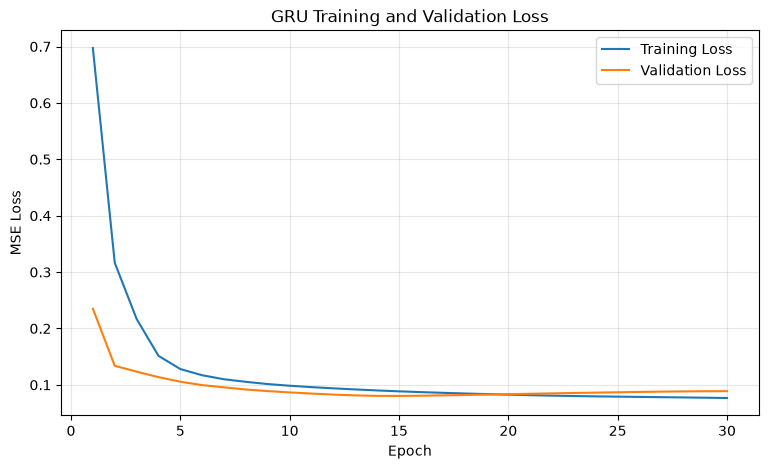

In [82]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, epochs + 1),
    train_losses,
    label="Training Loss"
)

plt.plot(
    range(1, epochs + 1),
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("GRU Training and Validation Loss")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [83]:
model.eval()

gru_predictions_norm = []
gru_targets_norm = []

with torch.no_grad():

    for X_batch, y_batch in val_loader:

        X_batch = X_batch.to(device)

        predictions = model(X_batch)

        gru_predictions_norm.append(
            predictions.cpu().numpy()
        )

        gru_targets_norm.append(
            y_batch.numpy()
        )

In [84]:
gru_predictions_norm = np.concatenate(
    gru_predictions_norm,
    axis=0
)

gru_targets_norm = np.concatenate(
    gru_targets_norm,
    axis=0
)

In [85]:
print(gru_predictions_norm.shape)
print(gru_targets_norm.shape)

(2905, 24)
(2905, 24)


In [86]:
gru_predictions = denormalize_ot(
    gru_predictions_norm
)

gru_targets = denormalize_ot(
    gru_targets_norm
)

In [87]:
gru_mae, gru_rmse = calculate_metrics(
    gru_targets,
    gru_predictions
)

In [88]:
print(
    f"GRU MAE : "
    f"{gru_mae:.4f} °C"
)

print(
    f"GRU RMSE: "
    f"{gru_rmse:.4f} °C"
)

GRU MAE : 1.9967 °C
GRU RMSE: 2.5860 °C


In [90]:
current_baselines = baseline_results_df[
    (baseline_results_df["L"] == L)
    &
    (baseline_results_df["H"] == H)
].copy()

In [91]:
model_results = pd.DataFrame([
    {
        "L": L,
        "H": H,
        "Model": "Linear Regression",
        "MAE": linear_mae,
        "RMSE": linear_rmse
    },

    {
        "L": L,
        "H": H,
        "Model": "GRU",
        "MAE": gru_mae,
        "RMSE": gru_rmse
    }
])

In [92]:
step3_results = pd.concat(
    [
        current_baselines,
        model_results
    ],
    ignore_index=True
)

In [93]:
step3_results[
    ["MAE", "RMSE"]
] = step3_results[
    ["MAE", "RMSE"]
].round(4)

step3_results

,L,H,Model,MAE,RMSE
0,24,24,Naive,1.7837,2.3977
1,24,24,Seasonal Naive,1.9522,2.6665
2,24,24,Linear Regression,2.3428,4.4129
3,24,24,GRU,1.9967,2.5860


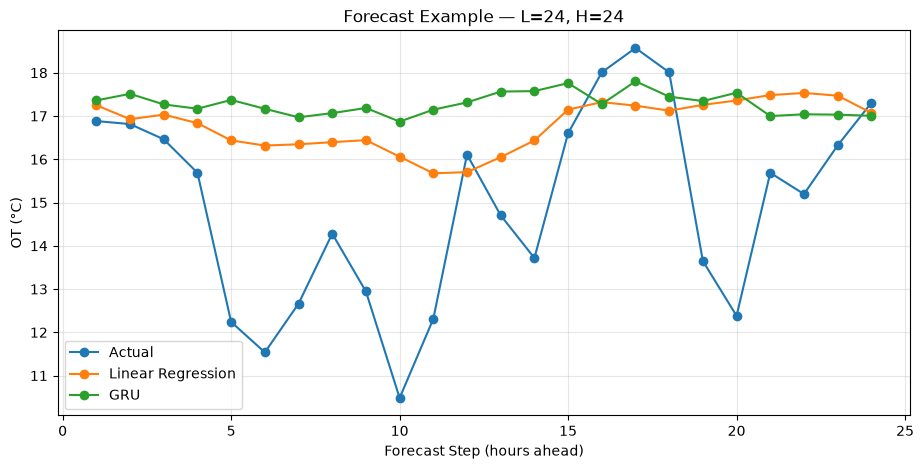

In [94]:
example = 0

plt.figure(figsize=(11, 5))

plt.plot(
    range(1, H + 1),
    gru_targets[example],
    marker="o",
    label="Actual"
)

plt.plot(
    range(1, H + 1),
    linear_val_pred[example],
    marker="o",
    label="Linear Regression"
)

plt.plot(
    range(1, H + 1),
    gru_predictions[example],
    marker="o",
    label="GRU"
)

plt.xlabel("Forecast Step (hours ahead)")
plt.ylabel("OT (°C)")

plt.title(
    f"Forecast Example — L={L}, H={H}"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()